In [2]:
%pip install pandas numpy matplotlib


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.8 MB 6.3 MB/s eta 0:00:01
     |████████████████████████████████| 5.3 MB 6.3 MB/s eta 0:00:01
     |████████████████████████████████| 7.8 MB 5.2 MB/s eta 0:00:01
     |████████████████████████████████| 506 kB 7.2 MB/s eta 0:00:01
     |████████████████████████████████| 348 kB 8.2 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 9.6 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 6.0 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 7.2 MB/s  eta 0:00:01
     |████████████████████████████████| 2.9 MB 8.1 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 9.9 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

np.random.seed(42)

n = 1000

products = {
    "Laptop": ("Electronics", 50000),
    "Mouse": ("Electronics", 800),
    "Keyboard": ("Electronics", 1500),
    "Chair": ("Furniture", 5000),
    "Desk": ("Furniture", 8000),
    "Notebook": ("Stationery", 100),
    "Pen": ("Stationery", 20),
    "Bottle": ("Accessories", 300)
}

product_names = list(products.keys())
chosen_products = np.random.choice(product_names, n)

df = pd.DataFrame({
    "Order_ID": [f"ORD{i:04d}" for i in range(1, n + 1)],
    "Order_Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31"),
            n
        )
    ),
    "Product": chosen_products,
    "Quantity": np.random.randint(1, 6, n)
})

df["Category"] = df["Product"].map(
    lambda x: products[x][0]
)

df["Unit_Price"] = df["Product"].map(
    lambda x: products[x][1]
)

df["Sales"] = df["Quantity"] * df["Unit_Price"]

df.to_csv("retail_sales.csv", index=False)

print("Dataset created successfully!")
print("Rows and columns:", df.shape)
df.head()

Dataset created successfully!
Rows and columns: (1000, 7)


,Order_ID,Order_Date,Product,Quantity,Category,Unit_Price,Sales
0,ORD0001,2025-05-25,Pen,2,Stationery,20,40
1,ORD0002,2025-07-20,Chair,3,Furniture,5000,15000
2,ORD0003,2025-07-31,Desk,2,Furniture,8000,16000
3,ORD0004,2025-08-08,Pen,2,Stationery,20,40
4,ORD0005,2025-08-28,Keyboard,5,Electronics,1500,7500


In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

products = {
    "Laptop": ("Electronics", 50000),
    "Mouse": ("Electronics", 800),
    "Keyboard": ("Electronics", 1500),
    "Chair": ("Furniture", 5000),
    "Desk": ("Furniture", 8000),
    "Notebook": ("Stationery", 100),
    "Pen": ("Stationery", 20),
    "Bottle": ("Accessories", 300)
}

product_names = list(products.keys())
chosen_products = np.random.choice(product_names, n)

df = pd.DataFrame({
    "Order_ID": [f"ORD{i:04d}" for i in range(1, n + 1)],
    "Order_Date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2025-12-31"),
            n
        )
    ),
    "Product": chosen_products,
    "Quantity": np.random.randint(1, 6, n)
})

df["Category"] = df["Product"].map(lambda x: products[x][0])
df["Unit_Price"] = df["Product"].map(lambda x: products[x][1])
df["Sales"] = df["Quantity"] * df["Unit_Price"]

df.to_csv("retail_sales.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset created successfully!
Dataset shape: (1000, 7)


,Order_ID,Order_Date,Product,Quantity,Category,Unit_Price,Sales
0,ORD0001,2025-05-25,Pen,2,Stationery,20,40
1,ORD0002,2025-07-20,Chair,3,Furniture,5000,15000
2,ORD0003,2025-07-31,Desk,2,Furniture,8000,16000
3,ORD0004,2025-08-08,Pen,2,Stationery,20,40
4,ORD0005,2025-08-28,Keyboard,5,Electronics,1500,7500


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    1000 non-null   object        
 1   Order_Date  1000 non-null   datetime64[ns]
 2   Product     1000 non-null   object        
 3   Quantity    1000 non-null   int64         
 4   Category    1000 non-null   object        
 5   Unit_Price  1000 non-null   int64         
 6   Sales       1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 54.8+ KB


In [6]:
df.isnull().sum()

Order_ID      0
Order_Date    0
Product       0
Quantity      0
Category      0
Unit_Price    0
Sales         0
dtype: int64

In [7]:
print("Total duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

Total duplicate rows: 0
Duplicate Order IDs: 0


In [8]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

print("Invalid dates:", df["Order_Date"].isna().sum())

Invalid dates: 0


In [9]:
print("Invalid quantity:", (df["Quantity"] <= 0).sum())
print("Invalid price:", (df["Unit_Price"] < 0).sum())
print("Invalid sales:", (df["Sales"] < 0).sum())

Invalid quantity: 0
Invalid price: 0
Invalid sales: 0


In [10]:
df = df.drop_duplicates().copy()

df["Sales"] = df["Quantity"] * df["Unit_Price"]

df.to_csv("retail_sales_cleaned.csv", index=False)

print("Data cleaning checks completed!")
print("Cleaned dataset saved successfully!")

Data cleaning checks completed!
Cleaned dataset saved successfully!


In [11]:
total_revenue = df["Sales"].sum()

print(f"Total Revenue: ₹{total_revenue:,.2f}")

Total Revenue: ₹26,396,680.00


In [12]:
total_orders = df["Order_ID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 1000


In [13]:
average_order_value = total_revenue / total_orders

print(f"Average Order Value: ₹{average_order_value:,.2f}")

Average Order Value: ₹26,396.68


In [14]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)
print("\nBest-performing category:", category_sales.idxmax())

Category
Electronics    21108500
Furniture       5122000
Accessories      123000
Stationery        43180
Name: Sales, dtype: int64

Best-performing category: Electronics


In [15]:
top_5_products = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print(top_5_products)

Product
Laptop      20300000
Desk         3072000
Chair        2050000
Keyboard      496500
Mouse         312000
Name: Sales, dtype: int64


In [16]:
df["Month"] = df["Order_Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .sort_index()
)

print(monthly_sales)

Month
2025-01    2586580
2025-02    2213040
2025-03    1221460
2025-04    3672800
2025-05    2512680
2025-06    1928040
2025-07    1936340
2025-08    2908820
2025-09    1270800
2025-10    1618020
2025-11    2295340
2025-12    2232760
Freq: M, Name: Sales, dtype: int64


Matplotlib is building the font cache; this may take a moment.


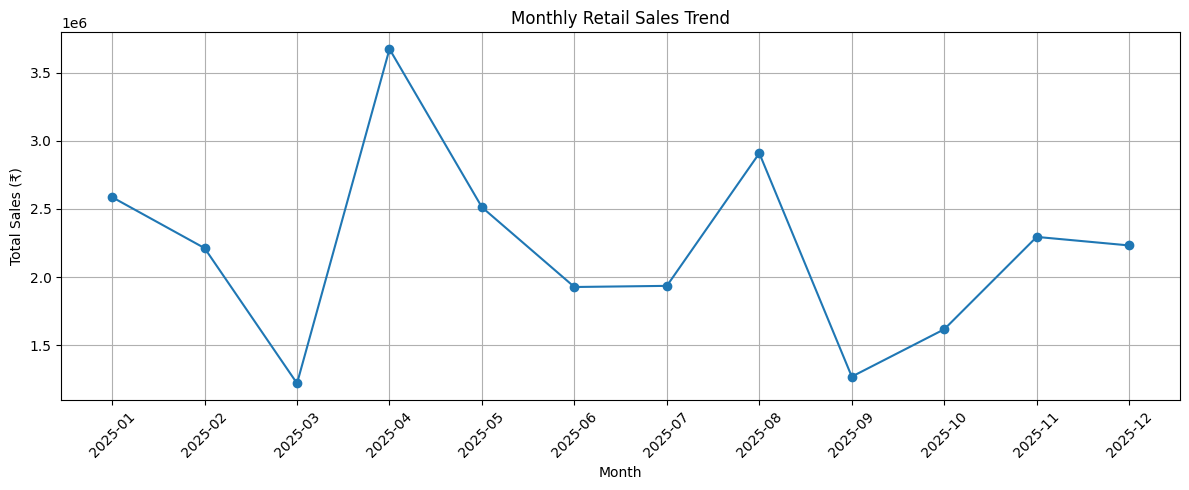

In [17]:
import matplotlib.pyplot as plt

monthly_sales_plot = monthly_sales.copy()
monthly_sales_plot.index = monthly_sales_plot.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales_plot.index,
    monthly_sales_plot.values,
    marker="o"
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

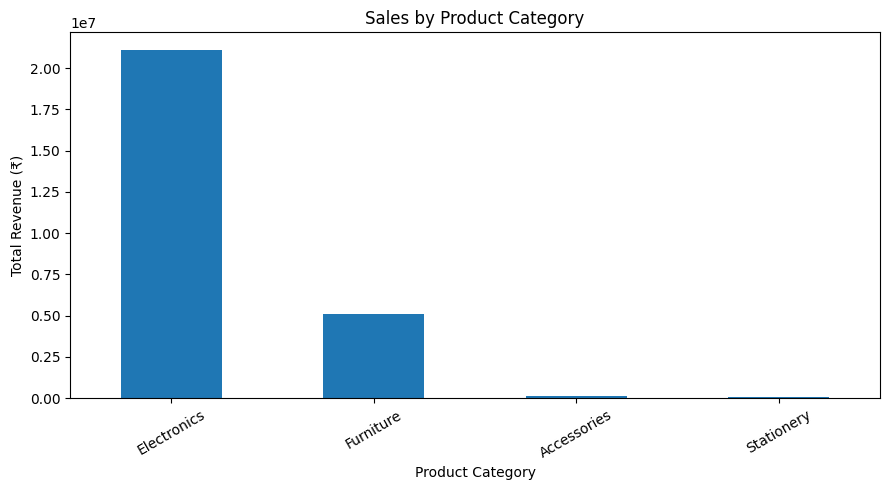

In [18]:
plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

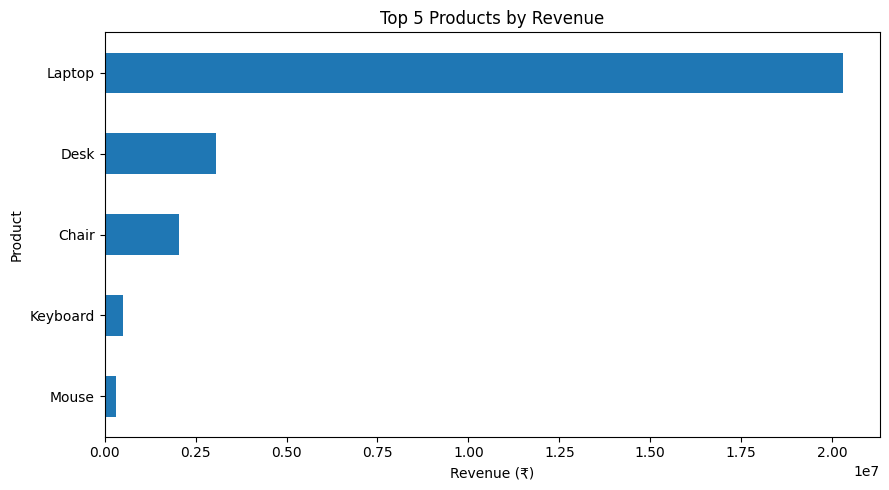

In [19]:
plt.figure(figsize=(9, 5))

top_5_products.sort_values().plot(kind="barh")

plt.title("Top 5 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()